# 1. Dataset overview

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(
    r"D:\Documents\slide unigap\ML\Dataset\Data\churn_training_set.csv"
)
print(df.shape)

(25559, 15)


In [4]:
train_df = df[
    df["split"] == "train"
].copy()

test_df = df[
    df["split"] == "test"
].copy()

print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (17183, 15)
Test: (8376, 15)


In [5]:
train_df.info()

<class 'pandas.DataFrame'>
Index: 17183 entries, 0 to 25557
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   shop_key            17183 non-null  str    
 1   snapshot_month      17183 non-null  str    
 2   tenure_in_months    17183 non-null  int64  
 3   bom_mrr             17183 non-null  float64
 4   eom_mrr             17183 non-null  float64
 5   gmv_growth_1m       14759 non-null  float64
 6   gmv_growth_2m       15061 non-null  float64
 7   searches_1m         17183 non-null  int64  
 8   searches_2m         17183 non-null  int64  
 9   searches_growth_1m  12669 non-null  float64
 10  searches_growth_2m  12947 non-null  float64
 11  churn_next_30d      17183 non-null  int64  
 12  split               17183 non-null  str    
 13  gmv_1m              17183 non-null  float64
 14  gmv_2m              17183 non-null  float64
dtypes: float64(8), int64(4), str(3)
memory usage: 2.8 MB


In [6]:
train_df.head()

,shop_key,snapshot_month,tenure_in_months,bom_mrr,eom_mrr,gmv_growth_1m,gmv_growth_2m,searches_1m,searches_2m,searches_growth_1m,searches_growth_2m,churn_next_30d,split,gmv_1m,gmv_2m
0,cus_02z6hpfbjryw7a,2026-06-01,0,0.000,330.109,NaN,NaN,0,0,NaN,NaN,0,train,0.0,0.0
1,cus_02z6hpfbjryw7a,2026-07-01,1,330.109,330.109,NaN,NaN,0,0,NaN,NaN,0,train,0.0,0.0
3,cus_0ay2nl5xmobqhj,2026-06-01,1,1799.280,1799.280,NaN,NaN,0,0,NaN,NaN,0,train,0.0,0.0
4,cus_0ay2nl5xmobqhj,2026-07-01,2,1799.280,1799.280,NaN,NaN,0,0,NaN,NaN,0,train,0.0,0.0
5,cus_2dl9sinz9re2oi,2026-06-01,8,253.260,253.260,NaN,NaN,0,0,NaN,NaN,0,train,0.0,0.0


In [7]:
churn_counts = train_df["churn_next_30d"].value_counts().sort_index()

print(churn_counts)

churn_next_30d
0    16721
1      462
Name: count, dtype: int64


In [8]:
churn_rate = (
    train_df["churn_next_30d"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print(churn_rate)

churn_next_30d
0    97.31
1     2.69
Name: proportion, dtype: float64


Key Observations
1. The dataset is highly imbalanced: churned merchants account for only 2.69% of the training set, significantly lower than non-churned merchants.

2. The model may be biased toward the majority class (non-churn): this could result in a high number of actual churn cases being misclassified as non-churn.

3. Accuracy is not an appropriate primary evaluation metric: a model that predicts all merchants as non-churn would still achieve 97.31% accuracy, despite failing to identify any churn cases.

In [9]:
train_df[
    ["tenure_in_months", "bom_mrr", "eom_mrr"]
].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure_in_months,17183.0,50.392015,25.170307,0.000000e+00,32.0,52.0,68.0,113.0
bom_mrr,17183.0,77.272943,146.060239,0.000000e+00,19.0,29.0,79.0,5500.0
eom_mrr,17183.0,80.739439,152.627366,1.016000e-13,19.0,29.0,79.0,5500.0


In [10]:

# Chia nhóm tenure
train_df["tenure_group"] = pd.cut(
    train_df["tenure_in_months"],
    bins=[-1, 12, 24, 36, 60, float("inf")],
    labels=["0-12", "13-24", "25-36", "37-60", "Over 60"]
)

# Tính churn rate
tenure_analysis = train_df.groupby(
    "tenure_group", observed=False
).agg(
    merchant_count=("churn_next_30d", "count"),
    churn_count=("churn_next_30d", "sum"),
    churn_rate=("churn_next_30d", "mean")
)

tenure_analysis["churn_rate"] = (
    tenure_analysis["churn_rate"] * 100
).round(2)

tenure_analysis

,merchant_count,churn_count,churn_rate
tenure_group,,,
0-12,1687,95,5.63
13-24,1250,39,3.12
25-36,2079,49,2.36
37-60,5834,154,2.64
Over 60,6333,125,1.97


--> The churn rate generally decreases as merchant tenure increases. Merchants with less than 12 months of tenure have a churn rate of 5.63%, nearly 2.9 times higher than those with over 60 months of tenure (1.97%). This suggests that newer merchants are at a higher risk of churning, although the downward trend is not strictly consistent across all tenure groups.

In [17]:

gmv_analysis = []

for col in ["gmv_1m", "gmv_2m"]:
    temp = train_df.copy()

    temp["gmv_status"] = np.where(
        temp[col] > 0,
        "Has GMV",
        "No GMV"
    )

    summary = (
        temp.groupby("gmv_status")
        .agg(
            merchant_months=("churn_next_30d", "count"),
            churned=("churn_next_30d", "sum"),
            churn_rate=("churn_next_30d", "mean")
        )
        .reset_index()
    )

    summary["gmv_period"] = col
    summary["churn_rate"] = summary["churn_rate"] * 100

    gmv_analysis.append(summary)

gmv_result = pd.concat(gmv_analysis, ignore_index=True)

gmv_result[
    ["gmv_period", "gmv_status", "merchant_months",
     "churned", "churn_rate"]
]

,gmv_period,gmv_status,merchant_months,churned,churn_rate
0,gmv_1m,Has GMV,14728,350,2.376426
1,gmv_1m,No GMV,2455,112,4.562118
2,gmv_2m,Has GMV,15114,374,2.474527
3,gmv_2m,No GMV,2069,88,4.253262


--> Merchants with no GMV exhibit substantially higher churn rates than those with positive GMV. The churn rate is 4.56% for merchants with no GMV in the current month, compared to 2.38% for active merchants. A similar pattern is observed over the past two months (4.25% vs. 2.47%). This suggests that the absence of GMV activity may be an important indicator of merchant churn risk.

In [18]:
gmv_cols = ["gmv_1m", "gmv_2m"]

gmv_stats = train_df[gmv_cols].describe(
    percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]
).T

gmv_stats["skewness"] = train_df[gmv_cols].skew()
gmv_stats["zero_count"] = (train_df[gmv_cols] == 0).sum()
gmv_stats["zero_pct"] = (
    (train_df[gmv_cols] == 0).mean() * 100
)

gmv_stats

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max,skewness,zero_count,zero_pct
gmv_1m,17183.0,254430.429624,4.678533e+06,0.0,1298.302196,19132.118791,107091.602825,392054.556725,8.067343e+05,2.945597e+06,5.638478e+08,104.894976,2455,14.287377
gmv_2m,17183.0,495243.091846,5.528098e+06,0.0,3132.025000,40357.691540,220510.200000,805179.638329,1.637705e+06,6.019703e+06,5.638489e+08,71.104304,2069,12.040971


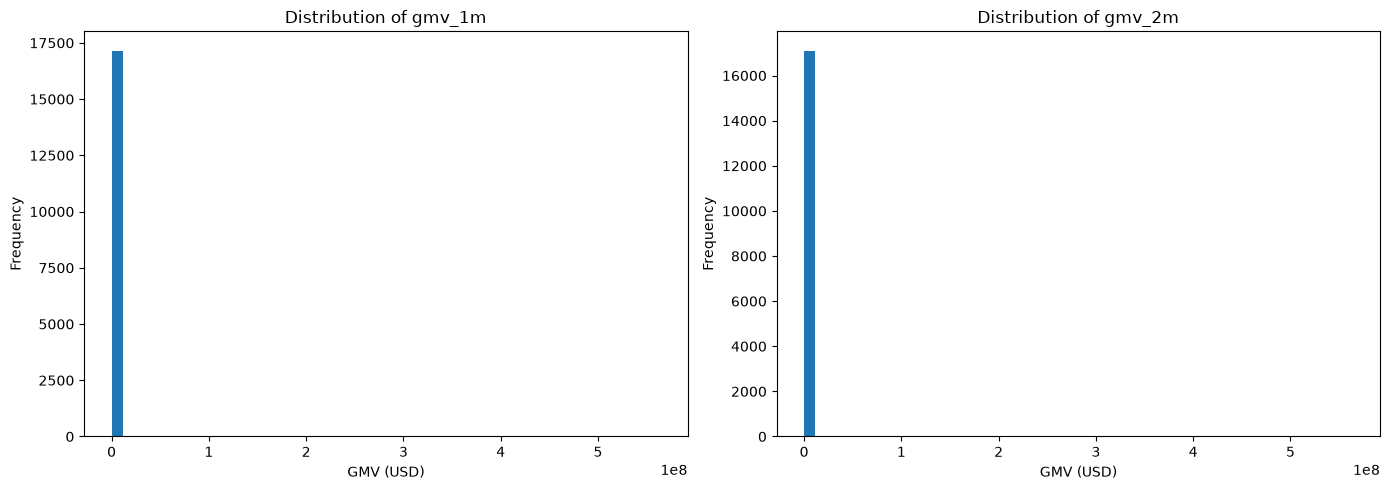

In [19]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, gmv_cols):
    ax.hist(train_df[col], bins=50)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("GMV (USD)")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [11]:
# Chia nhóm bom_mrr theo quantile
train_df["bom_mrr_group"] = pd.qcut(
    train_df["bom_mrr"],
    q=4,
    duplicates="drop"
)

# Tính churn rate
bom_mrr_analysis = train_df.groupby(
    "bom_mrr_group", observed=False
).agg(
    merchant_count=("churn_next_30d", "count"),
    churn_count=("churn_next_30d", "sum"),
    churn_rate=("churn_next_30d", "mean")
)

bom_mrr_analysis["churn_rate"] = (
    bom_mrr_analysis["churn_rate"] * 100
).round(2)

bom_mrr_analysis

,merchant_count,churn_count,churn_rate
bom_mrr_group,,,
"(-0.001, 19.0]",6081,159,2.61
"(19.0, 29.0]",3349,106,3.17
"(29.0, 79.0]",3945,93,2.36
"(79.0, 5500.0]",3808,104,2.73


--> The churn rate does not show a clear increasing or decreasing trend across BOM MRR groups. Merchants in the second quartile have the highest churn rate (3.17%), while those in the third quartile have the lowest (2.36%), suggesting that initial MRR alone may not be a strong indicator of churn risk.

In [12]:
train_df["eom_mrr_group"] = pd.qcut(
    train_df["eom_mrr"],
    q=4,
    duplicates="drop"
)

eom_mrr_analysis = train_df.groupby(
    "eom_mrr_group", observed=False
).agg(
    merchant_count=("churn_next_30d", "count"),
    churn_count=("churn_next_30d", "sum"),
    churn_rate=("churn_next_30d", "mean")
)

eom_mrr_analysis["churn_rate"] = (
    eom_mrr_analysis["churn_rate"] * 100
).round(2)

eom_mrr_analysis

,merchant_count,churn_count,churn_rate
eom_mrr_group,,,
"(-0.000999999999898, 19.0]",5849,121,2.07
"(19.0, 29.0]",3464,132,3.81
"(29.0, 79.0]",3945,93,2.36
"(79.0, 5500.0]",3925,116,2.96


--> The churn rate varies across EOM MRR groups without following a consistent trend. Merchants in the second quartile have the highest churn rate (3.81%), while those in the lowest quartile have the lowest (2.07%), suggesting that ending MRR alone does not exhibit a clear linear relationship with churn.

In [13]:
growth_analysis = train_df.groupby("churn_next_30d")[
    [
        "gmv_growth_1m",
        "gmv_growth_2m",
        "searches_growth_1m",
        "searches_growth_2m"
    ]
].median().T

growth_analysis.columns = ["Non-churn", "Churn"]
growth_analysis.round(3)

,Non-churn,Churn
gmv_growth_1m,-0.037,-0.203
gmv_growth_2m,-0.012,-0.109
searches_growth_1m,0.010,-0.151
searches_growth_2m,-0.039,-0.222


--> Churned merchants exhibit more negative GMV and search growth than non-churned merchants across all four features. This suggests that declining transaction value and search activity, particularly over the two-month period, may be associated with a higher likelihood of churn.

In [14]:
numeric_cols = [
    "tenure_in_months",
    "bom_mrr",
    "eom_mrr",
    "gmv_growth_1m",
    "gmv_growth_2m",
    "searches_1m",
    "searches_2m",
    "searches_growth_1m",
    "searches_growth_2m"
]

distribution_analysis = pd.DataFrame({
    "skewness": train_df[numeric_cols].skew(),
    "min": train_df[numeric_cols].min(),
    "median": train_df[numeric_cols].median(),
    "max": train_df[numeric_cols].max()
})

distribution_analysis.round(3)

,skewness,min,median,max
tenure_in_months,-0.106,0.0,52.000,1.130000e+02
bom_mrr,11.506,0.0,29.000,5.500000e+03
eom_mrr,10.655,0.0,29.000,5.500000e+03
gmv_growth_1m,119.966,-1.0,-0.040,5.252281e+05
gmv_growth_2m,121.766,-1.0,-0.014,3.155704e+05
searches_1m,33.714,0.0,548.000,8.332471e+06
searches_2m,34.218,0.0,1163.000,1.602954e+07
searches_growth_1m,104.808,-1.0,0.008,3.611550e+04
searches_growth_2m,99.226,-1.0,-0.042,4.493775e+04


--> Most numerical features exhibit substantial positive skewness, particularly GMV and search growth features, indicating extreme values and highly asymmetric distributions. Tenure is approximately symmetric, while MRR and activity-related features may require transformation or outlier treatment depending on the model.

In [15]:
growth_cols = [
    "gmv_growth_1m",
    "gmv_growth_2m",
    "searches_growth_1m",
    "searches_growth_2m"
]

missing_analysis = train_df.groupby("churn_next_30d")[
    growth_cols
].apply(lambda x: x.isna().mean() * 100).T

missing_analysis.columns = ["Non-churn (%)", "Churn (%)"]

missing_analysis.round(2)

,Non-churn (%),Churn (%)
gmv_growth_1m,13.87,22.73
gmv_growth_2m,12.18,18.61
searches_growth_1m,25.82,42.42
searches_growth_2m,24.28,38.10


--> Missing values are consistently more frequent among churned merchants than non-churned merchants across all four growth features. The difference is particularly notable for search growth, where missing rates are approximately 38–42% among churned merchants, compared with 24–26% among non-churned merchants, suggesting that missingness itself may contain useful predictive information.

In [16]:
monthly_churn = train_df.groupby("snapshot_month").agg(
    merchant_count=("churn_next_30d", "count"),
    churn_count=("churn_next_30d", "sum"),
    churn_rate=("churn_next_30d", "mean")
)

monthly_churn["churn_rate"] = (
    monthly_churn["churn_rate"] * 100
).round(2)

monthly_churn

,merchant_count,churn_count,churn_rate
snapshot_month,,,
2026-06-01,8670,247,2.85
2026-07-01,8513,215,2.53


--> The churn rate remains relatively stable between June and July 2026, decreasing slightly from 2.85% to 2.53% (a decline of 0.32 percentage points). This suggests that the target distribution is reasonably consistent across the two training snapshots.

EDA Summary
The exploratory data analysis revealed several key findings:

1. Churn by Tenure and MRR: Merchants with less than 12 months of tenure have the highest churn rate (5.63%). In contrast, MRR does not show a clear or consistent relationship with churn.

2. GMV and Search Activity: This analysis was skipped because the dataset does not contain absolute GMV values, making it impossible to reliably identify merchants with no GMV activity.

3. GMV and Search Growth: Churned merchants exhibit lower median growth rates than non-churned merchants across all four GMV and search growth features. This suggests that declining merchant activity may be associated with a higher likelihood of churn.

4. Feature Distribution and Outliers: MRR, GMV growth, and search-related features exhibit strong positive skewness, indicating the presence of extreme values. These features may require transformation or outlier treatment during preprocessing.

5. Missing Values: Missing rates are consistently higher among churned merchants, particularly for search growth features. This suggests that missingness may itself provide useful predictive information.

6. Churn Stability Over Time: The churn rate remains relatively stable across the two training snapshots, decreasing slightly from 2.85% in June 2026 to 2.53% in July 2026.

Recommendations for Modeling
Based on the EDA findings, the following approaches are recommended for the modeling stage:

1. Missing Value Handling: Apply median imputation combined with missing-value indicators for growth features to preserve potentially useful information from missingness.

2. Skewed Feature Transformation: Experiment with log1p transformations for MRR and search count features. Avoid applying standard logarithmic transformations directly to growth features because they contain negative values.

3. Outlier Treatment: Avoid removing outliers prematurely. Compare model performance using the original features against alternatives such as winsorization to determine whether outlier treatment improves predictive performance.

4. Feature Selection: Retain tenure, MRR, and GMV/search growth features initially, then evaluate their predictive contributions during model development.

5. Class Imbalance: Since churned merchants account for only 2.69% of the training set, prioritize evaluation metrics such as PR-AUC, Recall, Precision, and Recall@K rather than relying primarily on Accuracy.

6. Cross-validation Strategy: Use StratifiedGroupKFold with shop_key as the grouping variable to prevent the same merchant from appearing in both training and validation folds, reducing the risk of data leakage.

# II. Preprocessing

### 1. Define features, target

In [20]:
print("Các cột trong train_df:")
print(train_df.columns.tolist())

print("\nKiểu dữ liệu:")
print(train_df.dtypes)

Các cột trong train_df:
['shop_key', 'snapshot_month', 'tenure_in_months', 'bom_mrr', 'eom_mrr', 'gmv_growth_1m', 'gmv_growth_2m', 'searches_1m', 'searches_2m', 'searches_growth_1m', 'searches_growth_2m', 'churn_next_30d', 'split', 'gmv_1m', 'gmv_2m', 'tenure_group', 'bom_mrr_group', 'eom_mrr_group']

Kiểu dữ liệu:
shop_key                   str
snapshot_month             str
tenure_in_months         int64
bom_mrr                float64
eom_mrr                float64
gmv_growth_1m          float64
gmv_growth_2m          float64
searches_1m              int64
searches_2m              int64
searches_growth_1m     float64
searches_growth_2m     float64
churn_next_30d           int64
split                      str
gmv_1m                 float64
gmv_2m                 float64
tenure_group          category
bom_mrr_group         category
eom_mrr_group         category
dtype: object


In [21]:
target = "churn_next_30d"

exclude_cols = [
    "shop_key",
    "snapshot_month",
    "split",
    "churn_next_30d",
    "tenure_group",
    "bom_mrr_group",
    "eom_mrr_group"
]

feature_cols = [
    col for col in train_df.columns
    if col not in exclude_cols
]

X_train = train_df[feature_cols].copy()
y_train = train_df[target].copy()
groups = train_df["shop_key"].copy()

print("Features:", feature_cols)
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("Unique merchants:", groups.nunique())

Features: ['tenure_in_months', 'bom_mrr', 'eom_mrr', 'gmv_growth_1m', 'gmv_growth_2m', 'searches_1m', 'searches_2m', 'searches_growth_1m', 'searches_growth_2m', 'gmv_1m', 'gmv_2m']
X_train shape: (17183, 11)
y_train shape: (17183,)
Unique merchants: 8769


### 2. Missing value

In [22]:
missing_summary = pd.DataFrame({
    "missing_count": X_train.isnull().sum(),
    "missing_pct": X_train.isnull().mean() * 100
})

missing_summary = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_pct", ascending=False)
)

missing_summary

,missing_count,missing_pct
searches_growth_1m,4514,26.270151
searches_growth_2m,4236,24.652273
gmv_growth_1m,2424,14.106966
gmv_growth_2m,2122,12.349415


--> median imputation + missing indicator

In [23]:
# Kiểm tra giá trị âm
negative_summary = pd.DataFrame({
    "negative_count": (X_train.select_dtypes("number") < 0).sum()
})

negative_summary["negative_pct"] = (
    negative_summary["negative_count"] / len(X_train) * 100
)

negative_summary

,negative_count,negative_pct
tenure_in_months,0,0.000000
bom_mrr,0,0.000000
eom_mrr,0,0.000000
gmv_growth_1m,8135,47.343304
gmv_growth_2m,7803,45.411162
searches_1m,0,0.000000
searches_2m,0,0.000000
searches_growth_1m,6096,35.476925
searches_growth_2m,7297,42.466391
gmv_1m,0,0.000000


--> negative values in feature growth - keep

In [24]:
# Kiểm tra duplicate
print("Duplicate rows:", X_train.duplicated().sum())

# Kiểm tra infinite values
print(
    "Infinite values:",
    np.isinf(X_train.select_dtypes(include="number")).sum().sum()
)

Duplicate rows: 461
Infinite values: 0


In [25]:
# Kiểm tra trùng merchant trong cùng tháng
print(
    "Duplicate merchant-month:",
    train_df.duplicated(
        subset=["shop_key", "snapshot_month"]
    ).sum()
)

# Kiểm tra duplicate trên toàn bộ dữ liệu
print("Duplicate full rows:", train_df.duplicated().sum())

Duplicate merchant-month: 0
Duplicate full rows: 0


### 3. Distribution - log1p()

In [26]:
log_cols = [
    "bom_mrr",
    "eom_mrr",
    "gmv_1m",
    "gmv_2m",
    "searches_1m",
    "searches_2m"
]

X_train_log = X_train.copy()

for col in log_cols:
    X_train_log[col] = np.log1p(X_train_log[col])

In [27]:
skew_comparison = pd.DataFrame({
    "before": X_train[log_cols].skew(),
    "after": X_train_log[log_cols].skew()
})

skew_comparison

,before,after
bom_mrr,11.506450,0.163240
eom_mrr,10.654816,1.046202
gmv_1m,104.894976,-0.994223
gmv_2m,71.104304,-1.124250
searches_1m,33.714340,-0.194952
searches_2m,34.217938,-0.306699


--> improve more but gmv_1m, gmv_2m from right_skewed to left_skewed

### 4. Outliers

In [28]:
outlier_cols = [
    "bom_mrr",
    "eom_mrr",
    "gmv_1m",
    "gmv_2m",
    "searches_1m",
    "searches_2m"
]

outlier_summary = pd.DataFrame({
    "Q1": X_train[outlier_cols].quantile(0.25),
    "Q3": X_train[outlier_cols].quantile(0.75)
})

outlier_summary["IQR"] = (
    outlier_summary["Q3"] - outlier_summary["Q1"]
)

outlier_summary["upper_bound"] = (
    outlier_summary["Q3"] + 1.5 * outlier_summary["IQR"]
)

outlier_summary["outlier_count"] = [
    (X_train[col] > outlier_summary.loc[col, "upper_bound"]).sum()
    for col in outlier_cols
]

outlier_summary["outlier_pct"] = (
    outlier_summary["outlier_count"] / len(X_train) * 100
)

outlier_summary

,Q1,Q3,IQR,upper_bound,outlier_count,outlier_pct
bom_mrr,19.000000,79.000000,60.000000,169.000000,1708,9.940057
eom_mrr,19.000000,79.000000,60.000000,169.000000,1796,10.452191
gmv_1m,1298.302196,107091.602825,105793.300629,265781.553769,2398,13.955654
gmv_2m,3132.025000,220510.200000,217378.175000,546577.462500,2391,13.914916
searches_1m,0.000000,5108.500000,5108.500000,12771.250000,2631,15.311645
searches_2m,2.000000,10320.000000,10318.000000,25797.000000,2607,15.171972


--> 6 features all have outliers, range from 9.94% to 15.31% - keep

### 5. Scaling + Build preprocessing pipeline

In [29]:
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

In [30]:
# khai báo các nhóm features
log_cols = [
    "bom_mrr",
    "eom_mrr",
    "gmv_1m",
    "gmv_2m",
    "searches_1m",
    "searches_2m"
]

growth_cols = [
    "gmv_growth_1m",
    "gmv_growth_2m",
    "searches_growth_1m",
    "searches_growth_2m"
]

other_cols = [
    "tenure_in_months"
]

In [ ]:
# Pipeline cho các biến lệch phải, thực hiện log ngay trong pipeline, sau đó chuẩn hóa
log_pipeline = Pipeline([
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())
])

# Pipeline cho các biến growth, vừa điền missing bằng median, vừa đánh dấu cột missing.
growth_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# Pipeline cho tenure
other_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

In [ ]:
# processor kết hợp các pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("log", log_pipeline, log_cols),
        ("growth", growth_pipeline, growth_cols),
        ("other", other_pipeline, other_cols)
    ]
)

In [ ]:
# kết hợp Logistic Regression với preprocessor
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",   #giúp logistic regression chú ý hơn nhóm churn
        random_state=42
    ))
])

### 7. Cross_validation

In [33]:
from sklearn.model_selection import StratifiedGroupKFold

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups),
    start=1
):
    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    train_groups = groups.iloc[train_idx]
    val_groups = groups.iloc[val_idx]

    print(f"Fold {fold}")
    print("Train rows:", len(train_idx))
    print("Validation rows:", len(val_idx))

    print("Train churn rate:", round(y_fold_train.mean() * 100, 2), "%")
    print("Validation churn rate:", round(y_fold_val.mean() * 100, 2), "%")

    print("Group overlap:", len(set(train_groups) & set(val_groups)))
    print("-" * 40)

Fold 1
Train rows: 13746
Validation rows: 3437
Train churn rate: 2.69 %
Validation churn rate: 2.68 %
Group overlap: 0
----------------------------------------
Fold 2
Train rows: 13747
Validation rows: 3436
Train churn rate: 2.69 %
Validation churn rate: 2.68 %
Group overlap: 0
----------------------------------------
Fold 3
Train rows: 13746
Validation rows: 3437
Train churn rate: 2.68 %
Validation churn rate: 2.71 %
Group overlap: 0
----------------------------------------
Fold 4
Train rows: 13746
Validation rows: 3437
Train churn rate: 2.68 %
Validation churn rate: 2.71 %
Group overlap: 0
----------------------------------------
Fold 5
Train rows: 13747
Validation rows: 3436
Train churn rate: 2.69 %
Validation churn rate: 2.68 %
Group overlap: 0
----------------------------------------
